https://opendata.euskadi.eus/api-traffic/?api=traffic

In [44]:
import datetime as dt
import numpy as np
import pandas as pd
import requests

from dateutil import parser




In [45]:
"https://api.euskadi.eus/traffic/v1.0/flows/byDate/2025/5/17?_page=11"
#2025 5 de 17
#esto es el enlace de flow

'https://api.euskadi.eus/traffic/v1.0/flows/byDate/2025/5/17?_page=11'

In [46]:
df_correo=pd.read_csv("dataframede.csv")


dia_correo=[x.replace("-","/") for x in df_correo["Fecha"][0:len(df_correo["Fecha"])]]
dia_correo #saco del csv todos los dias que hibo noticia a pesar que no haga nada especial con ellos

['2025/05/19',
 '2025/05/14',
 '2025/05/12',
 '2025/05/11',
 '2025/05/10',
 '2025/05/09',
 '2025/05/09',
 '2025/05/06',
 '2025/05/06']

In [47]:
page=[str(x) for x in(range(1,5))] #esto es el numero de hojas que tiene el dia. Un dia parece que tien entre 1945 y 1970, el codigo con 5 hojas ya tarda bastante si  
date="2025/05/18" 
print(page)
url=f"https://api.euskadi.eus/traffic/v1.0/flows/byDate/{date}?_page={page}"

['1', '2', '3', '4']


In [48]:
d=pd.read_json(f"https://api.euskadi.eus/traffic/v1.0/flows/byDate/{date}?_page=200")
d["flows"][19] #Esta parte de la API se separa en 


{'meterId': '527',
 'sourceId': '5',
 'meterDate': '2025-05-18',
 'timeRank': '03:25',
 'speedAvg': '0',
 'totalVehicles': '0',
 'speedIntervals': [],
 'lengthIntervals': []}

Esta parte de la API se separa en:
* Dia: el byDate/{date}?
* Pagina: el _page_ (hay unas 1940 paginas al dia)
* Elementos (son 20 por pagina)

En cuanto a la informacion de cada elemento:
* Meter ID: esto creo que el km del sensor en la carretera
* Source ID: origen de la info (ver celda de abajo)
* Meter Date: Fecha
* tiime_rank: Hora
* Total vehicles: Vehiculos que pasaron
* speed intervals: Rango de velocidades en que pasaban. No suele aparecer
* length onterbals: no lo tengo claro, no suele aparecer


Tambien parece que las primeras paginas son las que cambian para meter mas informacion ya que el codigo simpre da un pico de 1000 coches por la mañana


In [49]:
d=pd.read_json("https://api.euskadi.eus/traffic/v1.0/sources?_page=1")
d

,id,descripcionEs,descripcionEu
0,1,Gobierno País Vasco,Eusko Jaurlaritza
1,2,Diputación Foral de Bizkaia,Bizkaia foru aldundia
2,3,Diputación Foral de Álava,Araba foru aldundia
3,4,Diputación Foral de Gipuzkoa,Gipuzkoa aldundia
4,5,Ayuntamiento Bilbao,Bilboko Udalaren
5,6,Ayuntamiento Vitoria-Gasteiz,Vitoria-Gasteizko Udala
6,7,Ayuntamiento de Donostia-San Sebastián,Donostiako Udala


In [ ]:
page=[str(x) for x in(range(0,100))]

In [ ]:
page=[str(x) for x in(range(1,100))]
# prtotipo para saber si es capaz de sacar los coches de forma automatica
lista_vehiculos=0
for pagina in page: # Solo  puse las 100 de 1940. Tardo 5 min, 43 s.  Para Sacar de un dia todos os cocher tardaria como 1 h
    for x in list(range(0,19)): #cada pagina tiene 20 elementos que van de 0 a 19 
        df = pd.read_json(f"https://api.euskadi.eus/traffic/v1.0/flows/byDate/{date}?_page={pagina}")
        #entron en api
        lista_vehiculos+=(int(df["flows"][x]["totalVehicles"])) #suma todos los veiculos de un dia delas primeras 5 hojas
lista_vehiculos # El codigo funciona y sacaria todos los vehiculos que se hayan ddetectado en el intervalo, pero desaformtunadamente el codigo es lento y creo que si un coche pasa por dos sensores contaria dos verces, lo coual no seria muy eficiente

405346

In [51]:
s=parser.parse(dia_correo[-1])
s

datetime.datetime(2025, 5, 6, 0, 0)

In [52]:
#saco el dia de hoy y lo pongo con guion para poder pasarlo a fecha de numpy
h=dt.datetime.now()
h
hnp=(f"{h.year}-0{h.month}-{h.day}")
print(hnp)

2025-05-20


In [53]:
# le le quito 13 porque no soy capaz de restar el rango, asi que le quito 14 y le sumo un rango de 14 dias
intervalo_numpy=np.arange(15)+(np.datetime64(hnp)-14)
intervalo_numpy# solo saco 14 dias porque tarda como 2 min es sacar los datos, 

array(['2025-05-06', '2025-05-07', '2025-05-08', '2025-05-09',
       '2025-05-10', '2025-05-11', '2025-05-12', '2025-05-13',
       '2025-05-14', '2025-05-15', '2025-05-16', '2025-05-17',
       '2025-05-18', '2025-05-19', '2025-05-20'], dtype='datetime64[D]')

In [54]:
#Paso el a array a lista, y paso cada elemento a str y paso los guiones a /. 
# Los array no se les puede hacer replace

intervalo_ultimos_14=[str(x).replace("-","/") for x in list(intervalo_numpy)]
intervalo_ultimos_14

['2025/05/06',
 '2025/05/07',
 '2025/05/08',
 '2025/05/09',
 '2025/05/10',
 '2025/05/11',
 '2025/05/12',
 '2025/05/13',
 '2025/05/14',
 '2025/05/15',
 '2025/05/16',
 '2025/05/17',
 '2025/05/18',
 '2025/05/19',
 '2025/05/20']

In [ ]:
#prototipo dias
lista_vehiculos={}
page=[str(x) for x in(range(1,5))]# para que sea todos los datos cambianr 5 por 1945
# itero en los ultimos 14 dias
for date in ((intervalo_ultimos_14)):
    #reseteo los vehiculos que panas por dia 
    vehiculos_dia=0
    for pagina in page:# primeras 5 paginas de 1945
        for x in list(range(0,19)): 
            df = pd.read_json(f"https://api.euskadi.eus/traffic/v1.0/flows/byDate/{date}?_page={pagina}")
            vehiculos_dia+=(int(df["flows"][x]["totalVehicles"]))
    lista_vehiculos[str(date)]=vehiculos_dia

lista_vehiculos # consigue sacar los cohes de las primeras 5 paginas. Es demasiado lento.


{'2025/05/06': 266,
 '2025/05/07': 246,
 '2025/05/08': 269,
 '2025/05/09': 273,
 '2025/05/10': 184,
 '2025/05/11': 75,
 '2025/05/12': 218,
 '2025/05/13': 250,
 '2025/05/14': 204,
 '2025/05/15': 232,
 '2025/05/16': 260,
 '2025/05/17': 159,
 '2025/05/18': 92,
 '2025/05/19': 231,
 '2025/05/20': 957}

In [56]:
serie_coches_dia=pd.Series(lista_vehiculos)
serie_coches_dia
#Esto se podria haber hecho con dlt mejor verdad pero no tuve tiempo de mirarmelo

2025/05/06    266
2025/05/07    246
2025/05/08    269
2025/05/09    273
2025/05/10    184
2025/05/11     75
2025/05/12    218
2025/05/13    250
2025/05/14    204
2025/05/15    232
2025/05/16    260
2025/05/17    159
2025/05/18     92
2025/05/19    231
2025/05/20    957
dtype: int64

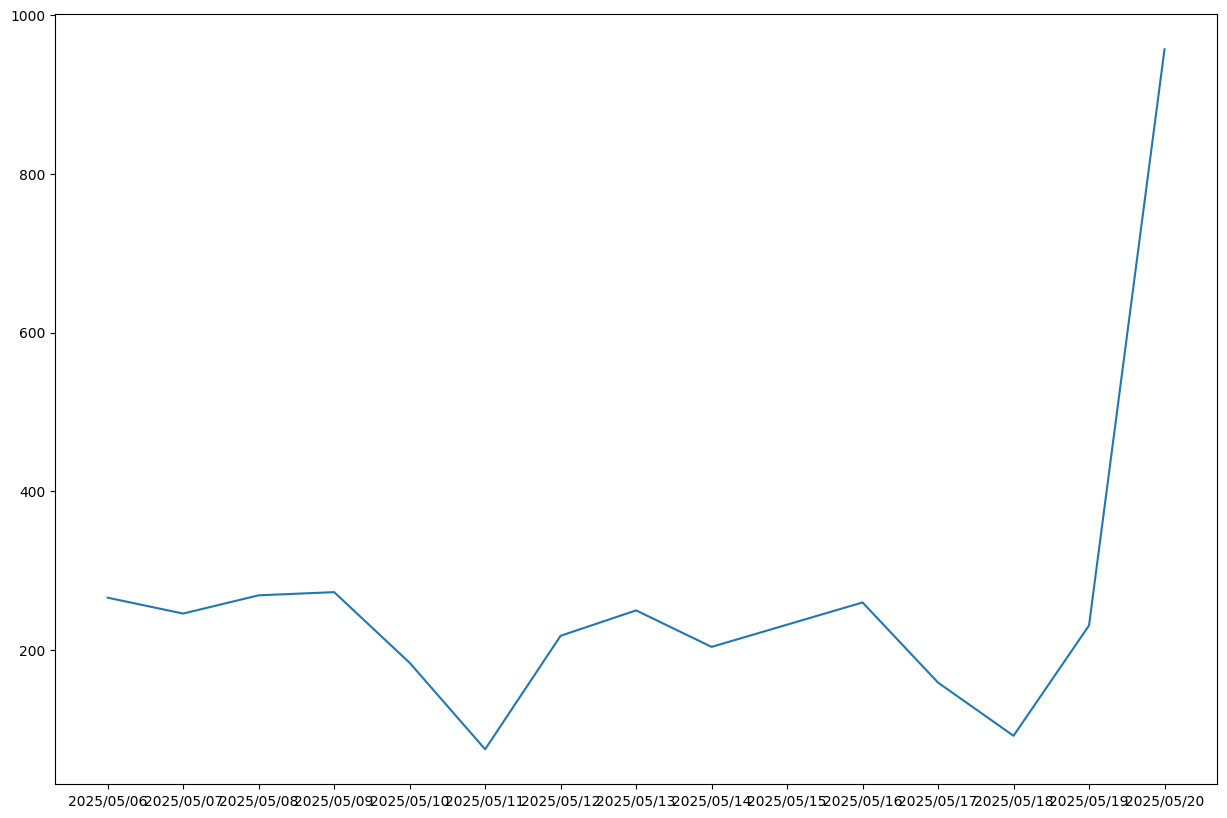

In [57]:
import	seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(15,10))
sns.lineplot(serie_coches_dia);


In [58]:
dia_correo

['2025/05/19',
 '2025/05/14',
 '2025/05/12',
 '2025/05/11',
 '2025/05/10',
 '2025/05/09',
 '2025/05/09',
 '2025/05/06',
 '2025/05/06']

In [59]:
df_correo

,Unnamed: 0,Titulo de noticia,Autor,Fecha,Hora,Fin_de_semana,Accidente,Atasco
0,0,Cuatro hombres se pegan tras un accidente de t...,David González,2025-05-19,00:20,0,1,1
1,1,Una colisión entre un camión y un coche obliga...,Nuria Nuño,2025-05-14,10:41,0,1,1
2,2,Una persona resulta herida en un accidente múl...,Leire Moro,2025-05-12,11:51,0,1,1
3,3,Un accidente en la entrada a Bilbao por San Ma...,Laura González,2025-05-11,12:52,1,1,1
4,4,Corte de carril en la autovía N-622 en Álava t...,Saioa Echeazarra,2025-05-10,08:45,1,1,1
5,5,"3,7 millones por el atropello de un niño: la m...",Rocío Mendoza| Madrid,2025-05-09,19:53,0,1,1
6,6,Un herido al volcar su furgoneta en la AP-68 a...,Nuria Nuño,2025-05-09,15:55,0,1,1
7,7,Colisión entre tres vehículos en la A-8 a la a...,L. Gil,2025-05-06,11:47,0,1,1
8,8,Las víctimas de accidentes rechazan las enmien...,Canal Motor,2025-05-06,01:17,0,1,1


Mi idea original era sacar todos los coches que  pasaron en las ultimas dos semanas y relacionarlas con las noticias. Pero viendo que para sacar lo de un dia se tardaria como 1 h he decidido no hacerlo por falta de tiempo. El codigo (eventualmente) lo sacaria pero es ineficiente.

Lo tambien intente hacer una version de esto con DTL, pero no me termino de funcionar.